Load libraries

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Read All Data Files

In [3]:
games_df = pd.read_csv(Path("..") / "data" / "raw" / "games.csv")
games_df

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
50867,2296380,I Expect You To Die 3: Cog in the Machine,2023-09-28,True,False,False,Very Positive,96,101,22.00,0.00,0.0,True
50868,1272080,PAYDAY 3,2023-09-21,True,False,False,Mostly Negative,38,29458,40.00,0.00,0.0,True
50869,1402110,Eternights,2023-09-11,True,False,False,Very Positive,89,1128,30.00,0.00,0.0,True
50870,2272250,Forgive Me Father 2,2023-10-19,True,False,False,Very Positive,95,82,17.00,0.00,0.0,True


In [4]:
recommendations_df = pd.read_csv(Path("..") / "data" / "raw" / "recommendations.csv")
recommendations_df

,app_id,helpful,funny,date,is_recommended,hours,user_id,review_id
0,975370,0,0,2022-12-12,True,36.3,51580,0
1,304390,4,0,2017-02-17,False,11.5,2586,1
2,1085660,2,0,2019-11-17,True,336.5,253880,2
3,703080,0,0,2022-09-23,True,27.4,259432,3
4,526870,0,0,2021-01-10,True,7.9,23869,4
...,...,...,...,...,...,...,...,...
41154789,633230,0,0,2021-02-15,True,41.0,1606890,41154789
41154790,758870,8,0,2019-07-18,False,8.0,1786254,41154790
41154791,696170,3,10,2018-03-26,False,2.0,6370324,41154791
41154792,696170,0,0,2018-06-11,True,4.0,1044289,41154792


In [5]:
users_df = pd.read_csv(Path("..") / "data" / "raw" / "users.csv")
users_df

,user_id,products,reviews
0,7360263,359,0
1,14020781,156,1
2,8762579,329,4
3,4820647,176,4
4,5167327,98,2
...,...,...,...
14306059,5047430,6,0
14306060,5048153,0,0
14306061,5059205,31,0
14306062,5074363,0,0


Preprocess Games.csv file

In [6]:
#Downcast dtypes
game_dtypes = {
    "app_id": "uint32",
    "title": "str",
    "win": "bool",
    "mac": "bool",
    "linux": "bool",
    "rating": "category",
    "positive_ratio": "uint8",
    "user_reviews": "uint32",
    "price_final": "float32",
    "price_original": "float32",
    "discount": "float32",
    "steam_deck": "bool",
}

games_df = games_df.astype(game_dtypes)

#Convert date_release column to datetime
games_df['date_release'] = pd.to_datetime(games_df['date_release'])

print(games_df.dtypes)


app_id                    uint32
title                        str
date_release      datetime64[us]
win                         bool
mac                         bool
linux                       bool
rating                  category
positive_ratio             uint8
user_reviews              uint32
price_final              float32
price_original           float32
discount                 float32
steam_deck                  bool
dtype: object


In [7]:
#Load games_metadata.json and merge to games.csv
games_meta = pd.read_json(Path("..") / "data" / "raw" / "games_metadata.json", lines=True)
games_meta["app_id"] = games_meta["app_id"].astype("uint32")
games_df = games_df.merge(games_meta, on="app_id", how="left")

games_df

,app_id,title,date_release,win,mac,linux,rating,positive_ratio,user_reviews,price_final,price_original,discount,steam_deck,description,tags
0,13500,Prince of Persia: Warrior Within™,2008-11-21,True,False,False,Very Positive,84,2199,9.99,9.99,0.0,True,Enter the dark underworld of Prince of Persia ...,"[Action, Adventure, Parkour, Third Person, Gre..."
1,22364,BRINK: Agents of Change,2011-08-03,True,False,False,Positive,85,21,2.99,2.99,0.0,True,,[Action]
2,113020,Monaco: What's Yours Is Mine,2013-04-24,True,True,True,Very Positive,92,3722,14.99,14.99,0.0,True,Monaco: What's Yours Is Mine is a single playe...,"[Co-op, Stealth, Indie, Heist, Local Co-Op, St..."
3,226560,Escape Dead Island,2014-11-18,True,False,False,Mixed,61,873,14.99,14.99,0.0,True,Escape Dead Island is a Survival-Mystery adven...,"[Zombies, Adventure, Survival, Action, Third P..."
4,249050,Dungeon of the ENDLESS™,2014-10-27,True,True,False,Very Positive,88,8784,11.99,11.99,0.0,True,Dungeon of the Endless is a Rogue-Like Dungeon...,"[Roguelike, Strategy, Tower Defense, Pixel Gra..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50867,2296380,I Expect You To Die 3: Cog in the Machine,2023-09-28,True,False,False,Very Positive,96,101,22.00,0.00,0.0,True,,[]
50868,1272080,PAYDAY 3,2023-09-21,True,False,False,Mostly Negative,38,29458,40.00,0.00,0.0,True,,[]
50869,1402110,Eternights,2023-09-11,True,False,False,Very Positive,89,1128,30.00,0.00,0.0,True,,[]
50870,2272250,Forgive Me Father 2,2023-10-19,True,False,False,Very Positive,95,82,17.00,0.00,0.0,True,Embark on a journey into the darkest nightmare...,"[Early Access, FPS, Action, Retro, First-Perso..."


Preprocess users.csv

In [8]:
user_dtypes = {
    "user_id": "uint32", 
    "products": "uint16",
    "reviews": "uint16"
}

users_df = users_df.astype(user_dtypes)

print(users_df.dtypes)

user_id     uint32
products    uint16
reviews     uint16
dtype: object


Preprocess recommendations.csv

In [9]:
rec_dtypes = {
    "app_id": "uint32",
    "helpful": "uint32",
    "funny": "uint32",
    "is_recommended": "bool",
    "hours": "float32",
    "user_id": "uint32",
    "review_id": "uint32",
}

#Downcast dtypes and check for nulls, outliers, etc.
recommendations_df_sample = pd.read_csv(Path("..") / "data" / "raw" / "recommendations.csv", dtype=rec_dtypes, parse_dates=["date"], nrows=500_000)

print(recommendations_df_sample.isnull().sum())
print(recommendations_df_sample['hours'].describe(percentiles=[0.5, 0.9, 0.99]))
print(recommendations_df_sample["is_recommended"].value_counts(normalize=True))

app_id            0
helpful           0
funny             0
date              0
is_recommended    0
hours             0
user_id           0
review_id         0
dtype: int64
count    500000.000000
mean        201.033676
std         236.677216
min           0.000000
50%         100.199997
90%         581.900024
99%         944.500000
max         999.900024
Name: hours, dtype: float64
is_recommended
True     0.84555
False    0.15445
Name: proportion, dtype: float64


Clean Text and Filter

In [10]:
games_df['title'] = games_df['title'].str.strip()
games_df['description'] = games_df['description'].fillna('').str.strip()
games_df['tags_str'] = games_df['tags'].apply(lambda x: ' '.join(x) if isinstance(x, list) else None)

games_filtered_df = games_df[games_df['user_reviews'] >= 20].copy()
valid_apps = set(games_filtered_df['app_id'])

chunks = []
for chunk in pd.read_csv(
    Path("..") / "data" / "raw" / "recommendations.csv",
    usecols=['user_id', 'app_id', 'date', 'is_recommended', 'hours'],
    dtype=rec_dtypes,
    parse_dates=['date'],
    chunksize=500_000
):
    chunk = chunk[chunk['app_id'].isin(valid_apps)]
    chunks.append(chunk)

recs = pd.concat(chunks, ignore_index=True)

recs = recs.dropna(subset=['user_id', 'app_id', 'date', 'hours', 'is_recommended'])
recs = recs[recs['hours'] >= 0]
recs = recs.sort_values("date").drop_duplicates(subset=['user_id', 'app_id'], keep='last')

user_counts = recs.groupby('user_id')['app_id'].count()
active_users = user_counts[user_counts >=10].index
recs = recs[recs['user_id'].isin(active_users)].copy()

sign = np.where(recs['is_recommended'], 1.0, -1.0).astype('float32')
recs['affinity'] = (sign * np.log1p(recs['hours'])).astype('float32')

print(f"Final cleaned interactions: {len(recs):,} | Active users: {recs['user_id'].nunique():,} | Games: {recs['app_id'].nunique():,}")

Final cleaned interactions: 14,512,458 | Active users: 679,224 | Games: 28,907


Create Charts to Visualize

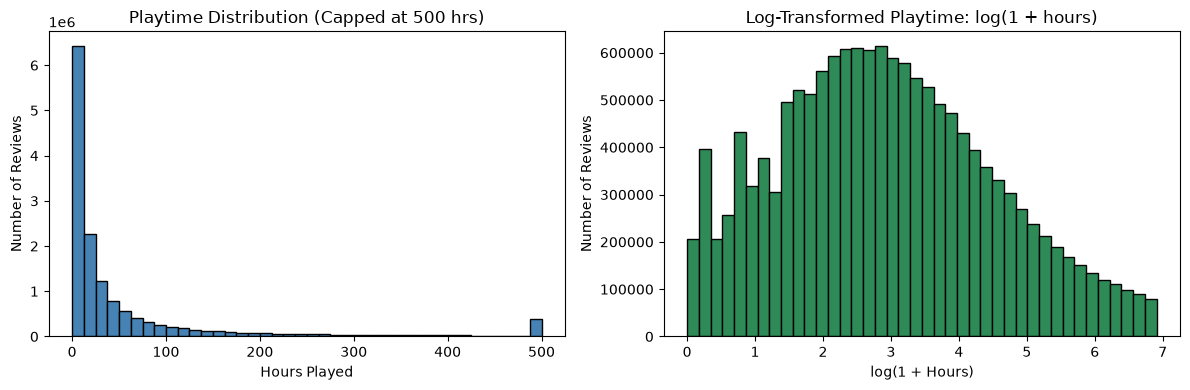

C:\Users\ragha\AppData\Local\Temp\ipykernel_28140\1212758777.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=games_filtered_df, y="rating", order=order, palette="viridis")


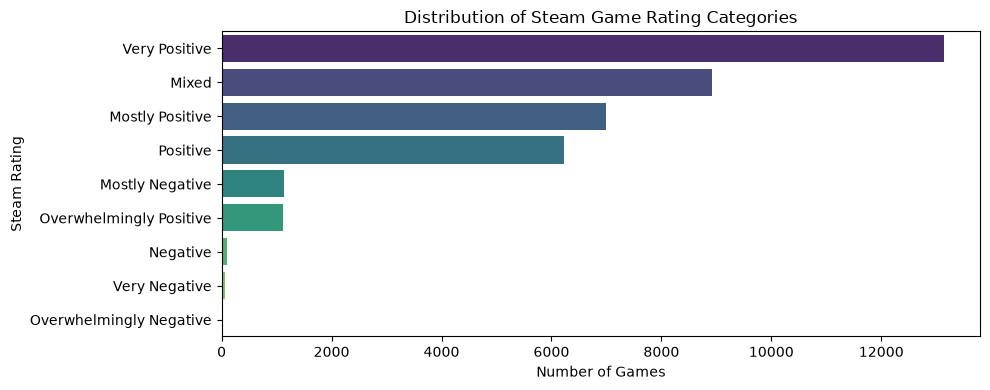

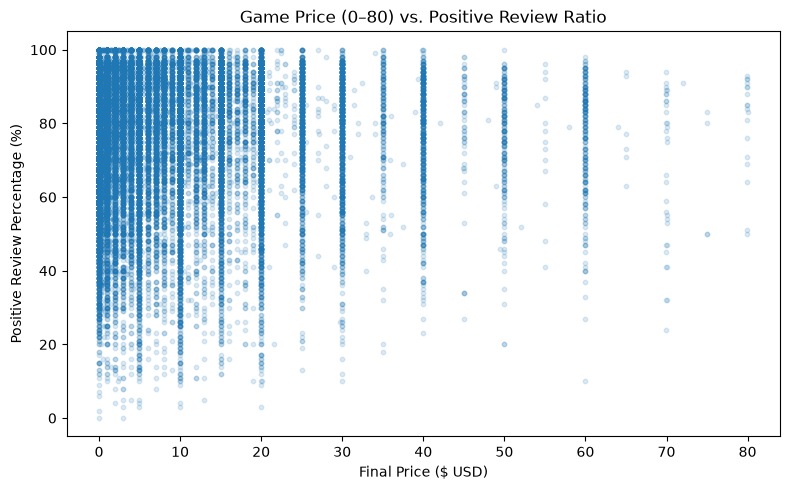

In [12]:
import os
os.makedirs("figures", exist_ok=True)

# Chart 1 (1D Quantitative Histogram - Lecture 5.1): Raw vs Log-Scaled Playtime
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(recs["hours"].clip(upper=500), bins=40, color="steelblue", edgecolor="black")
axes[0].set_title("Playtime Distribution (Capped at 500 hrs)")
axes[0].set_xlabel("Hours Played")
axes[0].set_ylabel("Number of Reviews")

axes[1].hist(np.log1p(recs["hours"]), bins=40, color="seagreen", edgecolor="black")
axes[1].set_title("Log-Transformed Playtime: log(1 + hours)")
axes[1].set_xlabel("log(1 + Hours)")
axes[1].set_ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig("figures/01_playtime_distribution.png", dpi=300)
plt.show()

# Chart 2 (1D Categorical Countplot - Lecture 5.1): Steam Rating Categories
plt.figure(figsize=(10, 4))
order = games_filtered_df["rating"].value_counts().index
sns.countplot(data=games_filtered_df, y="rating", order=order, palette="viridis")
plt.title("Distribution of Steam Game Rating Categories")
plt.xlabel("Number of Games")
plt.ylabel("Steam Rating")
plt.tight_layout()
plt.savefig("figures/02_rating_counts.png", dpi=300)
plt.show()

# Chart 3 (2D Relationship Scatter Plot - Lecture 5.1): Price vs Positive Ratio
sample_games = games_filtered_df[games_filtered_df["price_final"] <= 80]
plt.figure(figsize=(8, 5))
plt.scatter(sample_games["price_final"], sample_games["positive_ratio"], alpha=0.15, s=10)
plt.title("Game Price ($0–$80) vs. Positive Review Ratio")
plt.xlabel("Final Price ($ USD)")
plt.ylabel("Positive Review Percentage (%)")
plt.tight_layout()
plt.savefig("figures/03_price_vs_positive_ratio.png", dpi=300)
plt.show()